Task 4 Netflix Content Segmentation

1. Importing Libraries

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Load the dataset

In [40]:
df = pd.read_csv("Dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


3. Explore the dataset

In [41]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB

Missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Dupli

4. Select the features

In [42]:
features = [
    "type",
    "release_year",
    "duration",
    "listed_in",
    "country"
]

data = df[features].copy()

data.head()

,type,release_year,duration,listed_in,country
0,Movie,2020,90 min,Documentaries,United States
1,TV Show,2021,1 Season,"Crime TV Shows, International TV Shows, TV Act...",France
2,TV Show,2021,1 Season,"TV Dramas, TV Horror, TV Mysteries",United States
3,Movie,2021,91 min,"Children & Family Movies, Comedies",Brazil
4,Movie,1993,125 min,"Dramas, Independent Movies, International Movies",United States


5. Clean the data

In [43]:
categorical_columns = [
    "type",
    "duration",
    "listed_in",
    "country"
]

for col in categorical_columns:
    data[col] = data[col].fillna("Unknown")

data["release_year"] = data["release_year"].fillna(
    data["release_year"].median()
)

print(data.isnull().sum())

type            0
release_year    0
duration        0
listed_in       0
country         0
dtype: int64


6. Create a numerical duration feature

In [44]:
data["duration_number"] = (
    data["duration"]
    .str.extract(r"(\d+)", expand=False)
    .astype(float)
)

data["duration_number"] = data["duration_number"].fillna(0)

data[["duration", "duration_number"]].head(10)

,duration,duration_number
0,90 min,90.0
1,1 Season,1.0
2,1 Season,1.0
3,91 min,91.0
4,125 min,125.0
5,9 Seasons,9.0
6,104 min,104.0
7,87 min,87.0
8,127 min,127.0
9,76 min,76.0


7. Encode categorical features

In [45]:
X = data[
    [
        "type",
        "release_year",
        "duration_number",
        "listed_in",
        "country"
    ]
].copy()

X = pd.get_dummies(X, drop_first=False, dtype=float)

print("Feature matrix shape:", X.shape)
display(X.head())

Feature matrix shape: (8790, 603)


,release_year,duration_number,type_Movie,type_TV Show,listed_in_Action & Adventure,"listed_in_Action & Adventure, Anime Features","listed_in_Action & Adventure, Anime Features, Children & Family Movies","listed_in_Action & Adventure, Anime Features, Classic Movies","listed_in_Action & Adventure, Anime Features, Horror Movies","listed_in_Action & Adventure, Anime Features, International Movies",...,country_Turkey,country_Ukraine,country_United Arab Emirates,country_United Kingdom,country_United States,country_Uruguay,country_Venezuela,country_Vietnam,country_West Germany,country_Zimbabwe
0,2020,90.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,2021,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2021,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,2021,91.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1993,125.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


8. Scale the features

In [46]:
X = X.astype(float)

feature_means = X.mean(axis=0)
feature_stds = X.std(axis=0)

feature_stds[feature_stds == 0] = 1

X_scaled = (X - feature_means) / feature_stds

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (8790, 603)


9. Apply K-Means clustering

In [47]:
def kmeans_numpy(X, k=5, max_iter=100, random_state=42):
    X = np.asarray(X, dtype=float)

    rng = np.random.default_rng(random_state)
    indices = rng.choice(len(X), size=k, replace=False)
    centers = X[indices].copy()

    for _ in range(max_iter):
        distances = np.sqrt(
            ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        )
        labels = distances.argmin(axis=1)
        new_centers = centers.copy()

        for cluster_id in range(k):
            members = X[labels == cluster_id]
            if len(members) > 0:
                new_centers[cluster_id] = members.mean(axis=0)

        if np.allclose(centers, new_centers):
            centers = new_centers
            break

        centers = new_centers

    distances = np.sqrt(
        ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    )
    labels = distances.argmin(axis=1)

    return labels, centers

In [48]:
cluster_labels, cluster_centers = kmeans_numpy(
    X_scaled,
    k=5
)

data["cluster"] = cluster_labels

print("Clustering completed successfully!")
print(data["cluster"].value_counts().sort_index())


Clustering completed successfully!
cluster
0      68
1     356
2     140
3      57
4    8169
Name: count, dtype: int64


10. Visualize the cluster sizes

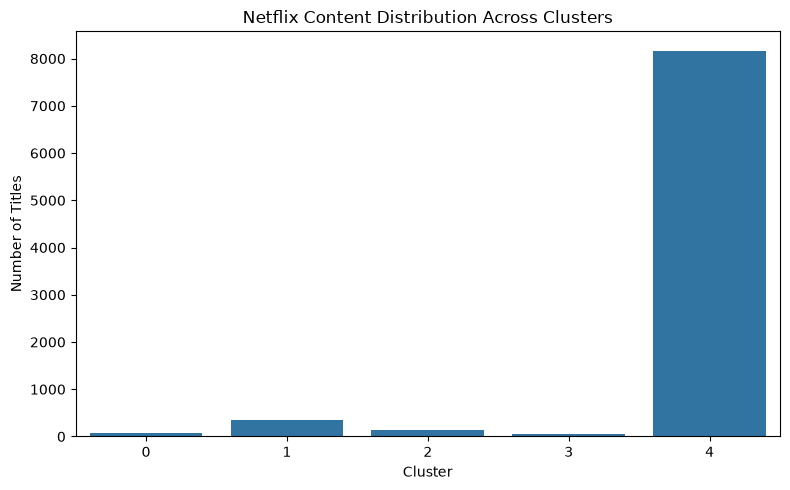

In [49]:
cluster_counts = data["cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_counts.index, y=cluster_counts.values)

plt.title("Netflix Content Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

11. Visualize the clusters in 2D

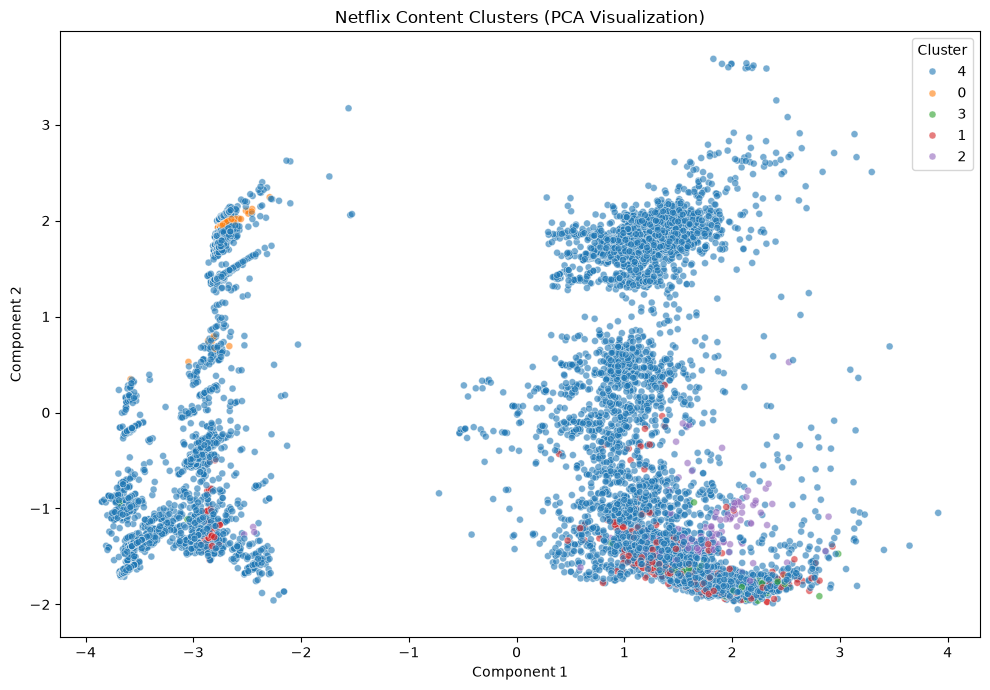

In [50]:
X_centered = X_scaled - X_scaled.mean(axis=0)

U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

X_2d = U[:, :2] * S[:2]

plot_data = pd.DataFrame({
    "Component 1": X_2d[:, 0],
    "Component 2": X_2d[:, 1],
    "Cluster": cluster_labels.astype(str)
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=plot_data,
    x="Component 1",
    y="Component 2",
    hue="Cluster",
    palette="tab10",
    alpha=0.6,
    s=25
)

plt.title("Netflix Content Clusters (PCA Visualization)")
plt.tight_layout()
plt.show()

PCA reduces the many feature columns into two dimensions for visualization. Each dot represents a title, and its color represents its assigned cluster.

12. Interpret the clusters

In [51]:
print("Content types by cluster:")
display(pd.crosstab(data["cluster"], data["type"]))

print("\nAverage release year by cluster:")
display(data.groupby("cluster")["release_year"].mean().round(1))

print("\nMost common genres in each cluster:")

for cluster_id in sorted(data["cluster"].unique()):
    print(f"\nCluster {cluster_id}")

    titles = data.loc[
        data["cluster"] == cluster_id,
        "listed_in"
    ]

    print(titles.value_counts().head(5))

Content types by cluster:


type,Movie,TV Show
cluster,,
0,0,68
1,303,53
2,137,3
3,55,2
4,5631,2538



Average release year by cluster:


cluster
0    2016.8
1    2015.8
2    2006.8
3    2011.7
4    2014.2
Name: release_year, dtype: float64


Most common genres in each cluster:

Cluster 0
listed_in
TV Comedies    68
Name: count, dtype: int64

Cluster 1
listed_in
Dramas, International Movies, Romantic Movies                        180
Crime TV Shows, International TV Shows, Spanish-Language TV Shows     16
International Movies, Thrillers                                       13
Dramas, International Movies                                          12
Dramas, International Movies, Thrillers                               11
Name: count, dtype: int64

Cluster 2
listed_in
Action & Adventure, Comedies, International Movies       70
Action & Adventure, International Movies                 19
Action & Adventure, Dramas, International Movies          8
Comedies, International Movies, Romantic Movies           6
Action & Adventure, Cult Movies, International Movies     5
Name: count, dtype: int64

Cluster 3
listed_in
Comedies, International Movies, Music & Musicals        55
Crime TV Shows, Spanish-Language TV Shows, TV Dramas     2


13. Save the results

In [52]:
data.to_csv("Netflix_Content_Segmentation_Results.csv", index=False)

print("Clustered dataset saved successfully!")

Clustered dataset saved successfully!
